# Importing Libraries

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
import os
import glob
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split, cross_val_score,GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.datasets import make_classification
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

pd.set_option('display.max_rows', 500)
pd.set_option('display.max_columns', 500)
pd.set_option('display.width', 1000)
warnings.filterwarnings('ignore')

# Reading of Data

In [3]:
df=pd.read_csv("C:\\Users\\dpree\\Desktop\\Kolate.AI\\1183\\Regression Model (Tumour Size,New Lesions)\\Input\\1183_Final_Dataset.csv")

In [4]:
df.head()

,Unnamed: 0,SUBJID,LBTEST,LBBASE,LBSTRESN,VISITDY_x,LSCAT,LSNEW,LSSLD,LSLD,LSSITE,LSNEWANY,VISITDY_y,RSNEW,PFSDYCR,PFSCR,AEPT,AECONT,Severity_1.0,Severity_2.0,Severity_3.0,Severity_4.0
0,0,3,Albumin,N,36.84,-11.0,Target lesion,N,118.0,39.0,Liver,N,-11.0,N,54.0,1.0,Dermatitis acneiform,N,2,0,0,0
1,1,3,Albumin,N,36.84,-11.0,Target lesion,N,118.0,39.0,Liver,N,55.0,Y,54.0,1.0,Dermatitis acneiform,N,2,0,0,0
2,2,3,Albumin,N,36.84,-11.0,Target lesion,N,118.0,39.0,Liver,N,55.0,N,54.0,1.0,Dermatitis acneiform,N,2,0,0,0
3,3,3,Albumin,N,36.84,-11.0,Target lesion,N,65.0,35.0,Liver,N,-11.0,N,54.0,1.0,Dermatitis acneiform,N,2,0,0,0
4,4,3,Albumin,N,36.84,-11.0,Target lesion,N,65.0,35.0,Liver,N,55.0,Y,54.0,1.0,Dermatitis acneiform,N,2,0,0,0


In [5]:
df= df.drop(columns=['Unnamed: 0','AEPT', 'AECONT', 'Severity_1.0', 'Severity_2.0','Severity_3.0', 'Severity_4.0'])

In [6]:
df.shape

(7100293, 15)

In [7]:
df.head()

,SUBJID,LBTEST,LBBASE,LBSTRESN,VISITDY_x,LSCAT,LSNEW,LSSLD,LSLD,LSSITE,LSNEWANY,VISITDY_y,RSNEW,PFSDYCR,PFSCR
0,3,Albumin,N,36.84,-11.0,Target lesion,N,118.0,39.0,Liver,N,-11.0,N,54.0,1.0
1,3,Albumin,N,36.84,-11.0,Target lesion,N,118.0,39.0,Liver,N,55.0,Y,54.0,1.0
2,3,Albumin,N,36.84,-11.0,Target lesion,N,118.0,39.0,Liver,N,55.0,N,54.0,1.0
3,3,Albumin,N,36.84,-11.0,Target lesion,N,65.0,35.0,Liver,N,-11.0,N,54.0,1.0
4,3,Albumin,N,36.84,-11.0,Target lesion,N,65.0,35.0,Liver,N,55.0,Y,54.0,1.0


In [8]:
df = df.drop_duplicates(keep='first')

In [9]:
def find_min_max_lssld_excl_zero(subjid_group):
    non_zero_lssld = subjid_group[subjid_group['LSSLD'] != 0]
    if not non_zero_lssld.empty:
        min_visitdy_y = non_zero_lssld['VISITDY_y'].min()
        max_visitdy_y = non_zero_lssld['VISITDY_y'].max()
        min_lssld = non_zero_lssld.loc[non_zero_lssld['VISITDY_y'] == min_visitdy_y, 'LSSLD'].min()
        max_lssld = non_zero_lssld.loc[non_zero_lssld['VISITDY_y'] == max_visitdy_y, 'LSSLD'].max()
        change_in_tumor_size = max_lssld - min_lssld
        return pd.Series({
            'min_VISITDY_y': min_visitdy_y,
            'min_LSSLD': min_lssld,
            'max_VISITDY_y': max_visitdy_y,
            'max_LSSLD': max_lssld,
            'LSSLD_Diff': change_in_tumor_size,
            'Percentage_LSSLD_Change': (change_in_tumor_size / max_lssld) * 100 if min_lssld != 0 else None
        })
    else:
        return pd.Series({
            'min_VISITDY_y': None,
            'min_LSSLD': None,
            'max_VISITDY_y': None,
            'max_LSSLD': None,
            'LSSLD_Diff': None,
            'Percentage_LSSLD_Change': None
        })
results = df.groupby('SUBJID').apply(find_min_max_lssld_excl_zero).reset_index()
print(results)

     SUBJID  min_VISITDY_y  min_LSSLD  max_VISITDY_y  max_LSSLD  LSSLD_Diff  Percentage_LSSLD_Change
0         3          -11.0       65.0           55.0      118.0        53.0                44.915254
1         7          -14.0      136.0          343.0      575.0       439.0                76.347826
2         9           -2.0       30.0          344.0       85.0        55.0                64.705882
3        13           -1.0      166.0           74.0      238.0        72.0                30.252101
4        15          -24.0       49.0          284.0      159.0       110.0                69.182390
5        17           -4.0       39.0          320.0       82.0        43.0                52.439024
6        20           -1.0       89.0           57.0      144.0        55.0                38.194444
7        24           -9.0       11.0          380.0       90.0        79.0                87.777778
8        25          -13.0      103.0          114.0      203.0       100.0                

In [10]:
results['LSSLD_Change'] = np.where(results['Percentage_LSSLD_Change'] > 50, 1, 0)

In [11]:
df=df.merge(results,on='SUBJID',how='inner')

In [12]:
df.shape

(2051290, 22)

In [13]:
df.head()

,SUBJID,LBTEST,LBBASE,LBSTRESN,VISITDY_x,LSCAT,LSNEW,LSSLD,LSLD,LSSITE,LSNEWANY,VISITDY_y,RSNEW,PFSDYCR,PFSCR,min_VISITDY_y,min_LSSLD,max_VISITDY_y,max_LSSLD,LSSLD_Diff,Percentage_LSSLD_Change,LSSLD_Change
0,3,Albumin,N,36.84,-11.0,Target lesion,N,118.0,39.0,Liver,N,-11.0,N,54.0,1.0,-11.0,65.0,55.0,118.0,53.0,44.915254,0
1,3,Albumin,N,36.84,-11.0,Target lesion,N,118.0,39.0,Liver,N,55.0,Y,54.0,1.0,-11.0,65.0,55.0,118.0,53.0,44.915254,0
2,3,Albumin,N,36.84,-11.0,Target lesion,N,118.0,39.0,Liver,N,55.0,N,54.0,1.0,-11.0,65.0,55.0,118.0,53.0,44.915254,0
3,3,Albumin,N,36.84,-11.0,Target lesion,N,65.0,35.0,Liver,N,-11.0,N,54.0,1.0,-11.0,65.0,55.0,118.0,53.0,44.915254,0
4,3,Albumin,N,36.84,-11.0,Target lesion,N,65.0,35.0,Liver,N,55.0,Y,54.0,1.0,-11.0,65.0,55.0,118.0,53.0,44.915254,0


In [14]:
numerical_columns = ['LBSTRESN', 'VISITDY_x', 'LSSLD', 'LSLD', 'VISITDY_y', 'PFSDYCR', 'PFSCR']
binary_columns = ['LSNEW', 'LSNEWANY', 'RSNEW','LSCAT','LBBASE','LBTEST','LSSITE']

In [15]:
df_encoded = pd.get_dummies(df, columns=binary_columns, drop_first=True, prefix_sep='_')

In [16]:
reduced_df = df_encoded.groupby('SUBJID').agg(
    {col: 'mean' for col in numerical_columns}
).reset_index()

In [17]:
df.shape

(2051290, 22)

In [18]:
binary_encoded_columns = [col for col in df_encoded.columns if col not in df.columns]
for col in binary_encoded_columns:
    reduced_df[col] = df_encoded.groupby('SUBJID')[col].sum().values

In [20]:
reduced_df = reduced_df[['SUBJID']  + numerical_columns + binary_encoded_columns]

In [21]:
reduced_df.head()

,SUBJID,LBSTRESN,VISITDY_x,LSSLD,LSLD,VISITDY_y,PFSDYCR,PFSCR,LSNEW_Y,LSNEWANY_Y,RSNEW_Y,LSCAT_Non-target lesion,LSCAT_Target lesion,LBBASE_Y,LBTEST_Alkaline Phosphatase,LBTEST_Carcinoembryonic Antigen,LBTEST_Creatinine,LBTEST_Hemoglobin,LBTEST_Lactate Dehydrogenase,LBTEST_Platelets,LBTEST_White Blood Cells,LSSITE_Bone,LSSITE_Central Nervous System,LSSITE_Chest,LSSITE_Gastrointestinal,LSSITE_HEENT/Neck,LSSITE_Liver,LSSITE_Lymph Nodes,LSSITE_Musculoskeletal,LSSITE_Other,LSSITE_Pelvic Site,LSSITE_Pulmonary,LSSITE_Skin,LSSITE_Spleen
0,3,135.910100,26.714286,99.000000,35.727273,33.000000,54.0,1.0,48,288,336,480,480,504,126,126,126,126,126,126,126,0,48,0,0,0,528,144,0,96,0,96,0,0
1,7,153.863690,169.257426,284.521127,40.117647,171.571429,339.0,1.0,0,0,0,1568,9744,5656,1414,1414,1414,1414,1414,1414,1414,0,0,0,0,0,6272,4256,0,0,0,784,0,0
2,9,112.913064,175.000000,44.071429,20.142857,175.000000,301.0,1.0,0,0,0,3136,3136,3136,784,784,784,784,784,784,784,0,0,0,0,0,784,3920,0,0,784,784,0,0
3,13,190.772448,39.909091,206.210526,35.000000,49.000000,73.0,1.0,96,864,528,576,912,792,198,198,198,198,198,198,198,0,0,0,96,0,1008,192,0,0,96,96,0,0
4,15,97.912880,147.196429,93.613636,23.909091,140.500000,414.0,1.0,0,0,0,1152,4224,2688,672,672,672,672,672,672,672,0,0,0,0,0,2304,0,0,0,0,3072,0,0


In [22]:
df1=df[['SUBJID','LSNEWANY','min_VISITDY_y','min_LSSLD','max_VISITDY_y','max_LSSLD','LSSLD_Diff','Percentage_LSSLD_Change','LSSLD_Change']]

In [23]:
df1.head()

,SUBJID,LSNEWANY,min_VISITDY_y,min_LSSLD,max_VISITDY_y,max_LSSLD,LSSLD_Diff,Percentage_LSSLD_Change,LSSLD_Change
0,3,N,-11.0,65.0,55.0,118.0,53.0,44.915254,0
1,3,N,-11.0,65.0,55.0,118.0,53.0,44.915254,0
2,3,N,-11.0,65.0,55.0,118.0,53.0,44.915254,0
3,3,N,-11.0,65.0,55.0,118.0,53.0,44.915254,0
4,3,N,-11.0,65.0,55.0,118.0,53.0,44.915254,0


In [24]:
df1=df1.merge(reduced_df,on='SUBJID',how='inner')

In [25]:
df1 = df1.drop_duplicates(keep='first')

In [26]:
df1.shape

(458, 42)

In [27]:
df1.head()

,SUBJID,LSNEWANY,min_VISITDY_y,min_LSSLD,max_VISITDY_y,max_LSSLD,LSSLD_Diff,Percentage_LSSLD_Change,LSSLD_Change,LBSTRESN,VISITDY_x,LSSLD,LSLD,VISITDY_y,PFSDYCR,PFSCR,LSNEW_Y,LSNEWANY_Y,RSNEW_Y,LSCAT_Non-target lesion,LSCAT_Target lesion,LBBASE_Y,LBTEST_Alkaline Phosphatase,LBTEST_Carcinoembryonic Antigen,LBTEST_Creatinine,LBTEST_Hemoglobin,LBTEST_Lactate Dehydrogenase,LBTEST_Platelets,LBTEST_White Blood Cells,LSSITE_Bone,LSSITE_Central Nervous System,LSSITE_Chest,LSSITE_Gastrointestinal,LSSITE_HEENT/Neck,LSSITE_Liver,LSSITE_Lymph Nodes,LSSITE_Musculoskeletal,LSSITE_Other,LSSITE_Pelvic Site,LSSITE_Pulmonary,LSSITE_Skin,LSSITE_Spleen
0,3,N,-11.0,65.0,55.0,118.0,53.0,44.915254,0,135.910100,26.714286,99.000000,35.727273,33.000000,54.0,1.0,48,288,336,480,480,504,126,126,126,126,126,126,126,0,48,0,0,0,528,144,0,96,0,96,0,0
27,3,Y,-11.0,65.0,55.0,118.0,53.0,44.915254,0,135.910100,26.714286,99.000000,35.727273,33.000000,54.0,1.0,48,288,336,480,480,504,126,126,126,126,126,126,126,0,48,0,0,0,528,144,0,96,0,96,0,0
1008,7,N,-14.0,136.0,343.0,575.0,439.0,76.347826,1,153.863690,169.257426,284.521127,40.117647,171.571429,339.0,1.0,0,0,0,1568,9744,5656,1414,1414,1414,1414,1414,1414,1414,0,0,0,0,0,6272,4256,0,0,0,784,0,0
12320,9,N,-2.0,30.0,344.0,85.0,55.0,64.705882,1,112.913064,175.000000,44.071429,20.142857,175.000000,301.0,1.0,0,0,0,3136,3136,3136,784,784,784,784,784,784,784,0,0,0,0,0,784,3920,0,0,784,784,0,0
18592,13,N,-1.0,166.0,74.0,238.0,72.0,30.252101,0,190.772448,39.909091,206.210526,35.000000,49.000000,73.0,1.0,96,864,528,576,912,792,198,198,198,198,198,198,198,0,0,0,96,0,1008,192,0,0,96,96,0,0


In [28]:
result1=df1

In [29]:
result1.fillna(0, inplace=True)

In [30]:
result1['LSNEWANY'] = result1['LSNEWANY'].astype('category').cat.codes

In [31]:
result1.head()

,SUBJID,LSNEWANY,min_VISITDY_y,min_LSSLD,max_VISITDY_y,max_LSSLD,LSSLD_Diff,Percentage_LSSLD_Change,LSSLD_Change,LBSTRESN,VISITDY_x,LSSLD,LSLD,VISITDY_y,PFSDYCR,PFSCR,LSNEW_Y,LSNEWANY_Y,RSNEW_Y,LSCAT_Non-target lesion,LSCAT_Target lesion,LBBASE_Y,LBTEST_Alkaline Phosphatase,LBTEST_Carcinoembryonic Antigen,LBTEST_Creatinine,LBTEST_Hemoglobin,LBTEST_Lactate Dehydrogenase,LBTEST_Platelets,LBTEST_White Blood Cells,LSSITE_Bone,LSSITE_Central Nervous System,LSSITE_Chest,LSSITE_Gastrointestinal,LSSITE_HEENT/Neck,LSSITE_Liver,LSSITE_Lymph Nodes,LSSITE_Musculoskeletal,LSSITE_Other,LSSITE_Pelvic Site,LSSITE_Pulmonary,LSSITE_Skin,LSSITE_Spleen
0,3,0,-11.0,65.0,55.0,118.0,53.0,44.915254,0,135.910100,26.714286,99.000000,35.727273,33.000000,54.0,1.0,48,288,336,480,480,504,126,126,126,126,126,126,126,0,48,0,0,0,528,144,0,96,0,96,0,0
27,3,1,-11.0,65.0,55.0,118.0,53.0,44.915254,0,135.910100,26.714286,99.000000,35.727273,33.000000,54.0,1.0,48,288,336,480,480,504,126,126,126,126,126,126,126,0,48,0,0,0,528,144,0,96,0,96,0,0
1008,7,0,-14.0,136.0,343.0,575.0,439.0,76.347826,1,153.863690,169.257426,284.521127,40.117647,171.571429,339.0,1.0,0,0,0,1568,9744,5656,1414,1414,1414,1414,1414,1414,1414,0,0,0,0,0,6272,4256,0,0,0,784,0,0
12320,9,0,-2.0,30.0,344.0,85.0,55.0,64.705882,1,112.913064,175.000000,44.071429,20.142857,175.000000,301.0,1.0,0,0,0,3136,3136,3136,784,784,784,784,784,784,784,0,0,0,0,0,784,3920,0,0,784,784,0,0
18592,13,0,-1.0,166.0,74.0,238.0,72.0,30.252101,0,190.772448,39.909091,206.210526,35.000000,49.000000,73.0,1.0,96,864,528,576,912,792,198,198,198,198,198,198,198,0,0,0,96,0,1008,192,0,0,96,96,0,0


#  Regression for New Lesions

# Linear Regression for New Lesions

In [34]:
X = result1.drop(columns=['SUBJID', 'LSNEWANY'])  
y = result1['LSNEWANY']

In [35]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [36]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [37]:
model11 = LinearRegression()

In [38]:
model11.fit(X_train_scaled, y_train)

LinearRegression()

In [39]:
y_test_pred = model11.predict(X_test_scaled)
mse = mean_squared_error(y_test, y_test_pred)
print(f"Mean Squared Error: {mse}")

Mean Squared Error: 0.24613260032231143


In [40]:
print(f"Intercept: {model11.intercept_}")
print(f"Coefficients: {model11.coef_}")

Intercept: 0.28961748633879786
Coefficients: [ 0.0097184   0.04732509 -0.29883439  0.03360469  0.00830564  0.02658449
 -0.07025396 -0.01102726  0.04634154 -0.08611083 -0.02962157  0.44107743
 -0.1032322   0.05764003 -0.05381015 -0.01865782  0.37558052 -0.53343877
 -0.48860763  0.71278466 -0.50121964 -0.06272956  0.76247206  0.76247206
 -2.40559712  0.93612401  0.76247206 -0.00811708  0.003668    0.00671159
 -0.08756271  0.02891142 -0.11074062  0.0066763  -0.31844524  0.00815682
  0.05171141 -0.00382546 -0.06301557 -0.00661921]


In [41]:
print(f"Feature names: {X.columns.tolist()}")

Feature names: ['min_VISITDY_y', 'min_LSSLD', 'max_VISITDY_y', 'max_LSSLD', 'LSSLD_Diff', 'Percentage_LSSLD_Change', 'LSSLD_Change', 'LBSTRESN', 'VISITDY_x', 'LSSLD', 'LSLD', 'VISITDY_y', 'PFSDYCR', 'PFSCR', 'LSNEW_Y', 'LSNEWANY_Y', 'RSNEW_Y', 'LSCAT_Non-target lesion', 'LSCAT_Target lesion', 'LBBASE_Y', 'LBTEST_Alkaline Phosphatase', 'LBTEST_Carcinoembryonic Antigen', 'LBTEST_Creatinine', 'LBTEST_Hemoglobin', 'LBTEST_Lactate Dehydrogenase', 'LBTEST_Platelets', 'LBTEST_White Blood Cells', 'LSSITE_Bone', 'LSSITE_Central Nervous System', 'LSSITE_Chest', 'LSSITE_Gastrointestinal', 'LSSITE_HEENT/Neck', 'LSSITE_Liver', 'LSSITE_Lymph Nodes', 'LSSITE_Musculoskeletal', 'LSSITE_Other', 'LSSITE_Pelvic Site', 'LSSITE_Pulmonary', 'LSSITE_Skin', 'LSSITE_Spleen']


In [42]:
predictions_df = pd.DataFrame({
    'SUBJID': result1.loc[X_test.index, 'SUBJID'],  # Extract SUBJID from original dataset
    'LSNEWANY': y_test,
    'Predicted_New_Lesions': y_test_pred
})

In [43]:
predictions_df.head()

,SUBJID,LSNEWANY,Predicted_New_Lesions
1414583,799,0,-0.098915
163703,101,1,0.373221
1583842,888,0,0.032895
1026957,588,1,0.356749
746533,446,0,0.692358


# Feature Importance

                            Feature  Importance
24     LBTEST_Lactate Dehydrogenase   -2.405597
25                 LBTEST_Platelets    0.936124
23                LBTEST_Hemoglobin    0.762472
26         LBTEST_White Blood Cells    0.762472
22                LBTEST_Creatinine    0.762472
19                         LBBASE_Y    0.712785
17          LSCAT_Non-target lesion   -0.533439
20      LBTEST_Alkaline Phosphatase   -0.501220
18              LSCAT_Target lesion   -0.488608
11                        VISITDY_y    0.441077
16                          RSNEW_Y    0.375581
34           LSSITE_Musculoskeletal   -0.318445
2                     max_VISITDY_y   -0.298834
32                     LSSITE_Liver   -0.110741
12                          PFSDYCR   -0.103232
30          LSSITE_Gastrointestinal   -0.087563
9                             LSSLD   -0.086111
6                      LSSLD_Change   -0.070254
38                      LSSITE_Skin   -0.063016
21  LBTEST_Carcinoembryonic Antigen   -0

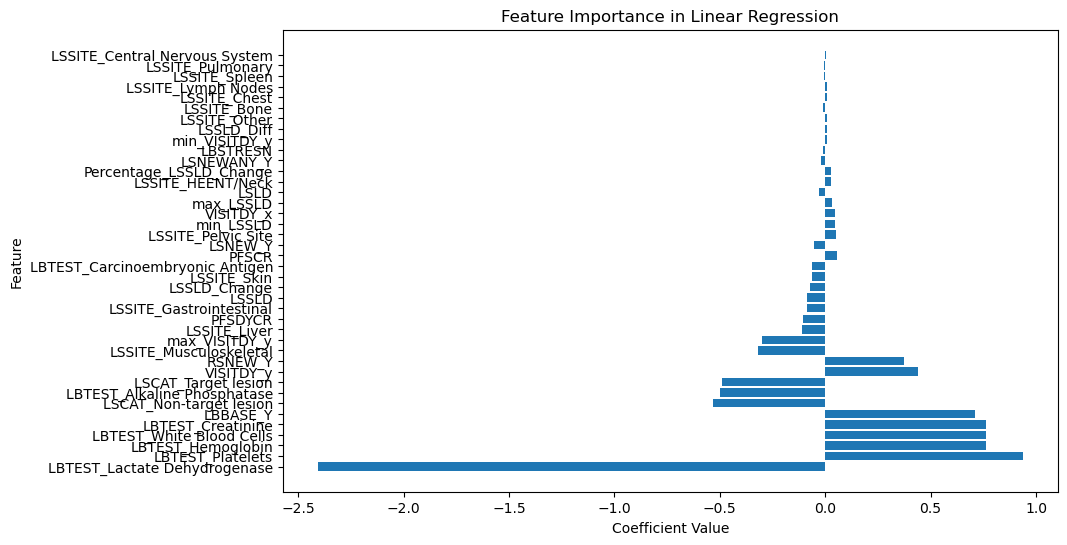

In [84]:
# Get the coefficients
coefficients = model11.coef_

importance_df = pd.DataFrame({
    'Feature': X.columns,
    'Importance': coefficients
})

importance_df['Abs_Importance'] = np.abs(importance_df['Importance'])
importance_df = importance_df.sort_values(by='Abs_Importance', ascending=False)

print(importance_df[['Feature', 'Importance']])

plt.figure(figsize=(10, 6))
plt.barh(importance_df['Feature'], importance_df['Importance'])
plt.xlabel('Coefficient Value')
plt.ylabel('Feature')
plt.title('Feature Importance in Linear Regression')
plt.show()

# Logistic Regression for New Lesions

In [155]:
X = result1.drop(columns=['SUBJID', 'LSNEWANY'])  
y = result1['LSNEWANY']

In [88]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [90]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [92]:
model12= LogisticRegression()

In [94]:
model12.fit(X_train_scaled, y_train)

LogisticRegression()

In [96]:
y_pred = model12.predict(X_test_scaled)

In [98]:
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy:.4f}")

Accuracy: 0.6957


In [100]:
conf_matrix = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:")
print(conf_matrix)

Confusion Matrix:
[[60  8]
 [20  4]]


In [102]:
class_report = classification_report(y_test, y_pred)
print("Classification Report:")
print(class_report)

Classification Report:
              precision    recall  f1-score   support

           0       0.75      0.88      0.81        68
           1       0.33      0.17      0.22        24

    accuracy                           0.70        92
   macro avg       0.54      0.52      0.52        92
weighted avg       0.64      0.70      0.66        92



In [104]:
result1['Predicted_New_Lesions'] = model12.predict(scaler.transform(X))

# Final output: One prediction per SUBJID
predictions = result1.drop_duplicates(subset='SUBJID')[['SUBJID', 'LSNEWANY', 'Predicted_New_Lesions']]
predictions.drop_duplicates(keep='first')

,SUBJID,LSNEWANY,Predicted_New_Lesions
0,3,0,0
1008,7,0,0
12320,9,0,0
18592,13,0,0
20176,15,0,0
25552,17,0,0
28720,20,0,0
29168,24,0,0
30688,25,0,0
32263,27,0,0


In [106]:
result1['SUBJID'].nunique()

335

In [108]:
predictions.head()

,SUBJID,LSNEWANY,Predicted_New_Lesions
0,3,0,0
1008,7,0,0
12320,9,0,0
18592,13,0,0
20176,15,0,0


# Feature Importance for Logistic Regression

In [165]:
X = result1.drop(columns=['SUBJID', 'LSNEWANY','LSSITE_Other'])  

In [167]:
print("Shape of model coefficients:", model12.coef_.shape)
print("Number of features:", X.shape[1])

Shape of model coefficients: (1, 40)
Number of features: 40


                            Feature  Importance
11                        VISITDY_y    1.389378
12                          PFSDYCR   -1.339276
13                            PFSCR    1.234389
16                          RSNEW_Y    1.136995
8                         VISITDY_x    0.593471
15                       LSNEWANY_Y    0.366700
30          LSSITE_Gastrointestinal   -0.361897
6                      LSSLD_Change   -0.349942
2                     max_VISITDY_y   -0.337617
10                             LSLD   -0.297575
17          LSCAT_Non-target lesion   -0.287019
5           Percentage_LSSLD_Change    0.258920
14                          LSNEW_Y   -0.255962
33               LSSITE_Lymph Nodes   -0.242844
38                    LSSITE_Spleen   -0.221977
31                LSSITE_HEENT/Neck    0.221279
1                         min_LSSLD    0.220844
24     LBTEST_Lactate Dehydrogenase   -0.216893
7                          LBSTRESN   -0.200243
19                         LBBASE_Y   -0

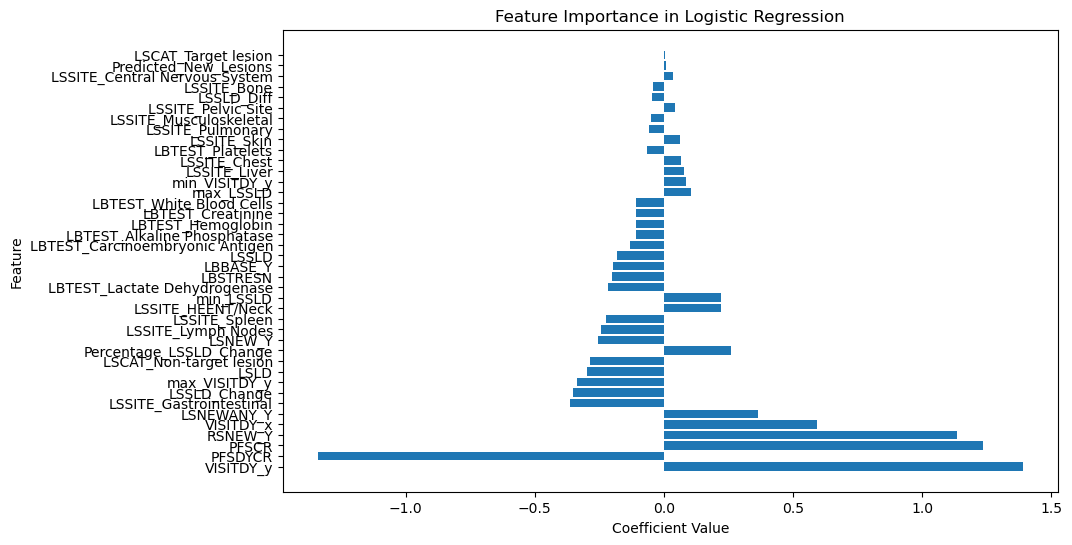

In [169]:

if len(model12.coef_) == 1:
    coefficients = model12.coef_[0]
else:
    coefficients = np.mean(model12.coef_, axis=0)

if len(coefficients) != len(X.columns):
    print("Mismatch between number of coefficients and number of features!")
else:
    importance_df = pd.DataFrame({
        'Feature': X.columns,
        'Importance': coefficients
    })

    importance_df['Abs_Importance'] = np.abs(importance_df['Importance'])
    importance_df = importance_df.sort_values(by='Abs_Importance', ascending=False)

    print(importance_df[['Feature', 'Importance']])

    plt.figure(figsize=(10, 6))
    plt.barh(importance_df['Feature'], importance_df['Importance'])
    plt.xlabel('Coefficient Value')
    plt.ylabel('Feature')
    plt.title('Feature Importance in Logistic Regression')
    plt.show()

# Selecting Features for Logistic New Lesions

In [249]:
result1.columns

Index(['SUBJID', 'LSNEWANY', 'min_VISITDY_y', 'min_LSSLD', 'max_VISITDY_y', 'max_LSSLD', 'LSSLD_Diff', 'Percentage_LSSLD_Change', 'LSSLD_Change', 'LBSTRESN', 'VISITDY_x', 'LSSLD', 'LSLD', 'VISITDY_y', 'PFSDYCR', 'PFSCR', 'LSNEW_Y', 'LSNEWANY_Y', 'RSNEW_Y', 'LSCAT_Non-target lesion', 'LSCAT_Target lesion', 'LBBASE_Y', 'LBTEST_Alkaline Phosphatase', 'LBTEST_Carcinoembryonic Antigen', 'LBTEST_Creatinine', 'LBTEST_Hemoglobin', 'LBTEST_Lactate Dehydrogenase', 'LBTEST_Platelets', 'LBTEST_White Blood Cells', 'LSSITE_Bone', 'LSSITE_Central Nervous System', 'LSSITE_Chest', 'LSSITE_Gastrointestinal', 'LSSITE_HEENT/Neck', 'LSSITE_Liver', 'LSSITE_Lymph Nodes', 'LSSITE_Musculoskeletal', 'LSSITE_Other', 'LSSITE_Pelvic Site', 'LSSITE_Pulmonary', 'LSSITE_Skin', 'LSSITE_Spleen', 'Predicted_New_Lesions'], dtype='object')

In [173]:
X = result1.drop(columns=['SUBJID', 'LSNEWANY','LSNEW_Y','LSNEWANY_Y','LSSITE_Bone', 'LSSITE_Central Nervous System', 'LSSITE_Chest', 'LSSITE_Gastrointestinal', 'LSSITE_HEENT/Neck', 'LSSITE_Liver', 'LSSITE_Lymph Nodes', 'LSSITE_Musculoskeletal', 'LSSITE_Other', 'LSSITE_Pelvic Site', 'LSSITE_Pulmonary', 'LSSITE_Skin', 'LSSITE_Spleen', 'Predicted_New_Lesions'])  
y = result1['LSNEWANY']

In [175]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [177]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [179]:
model13 = LogisticRegression()

In [181]:
model13.fit(X_train_scaled, y_train)

LogisticRegression()

In [183]:
y_train_pred = model13.predict(X_train_scaled)
y_test_pred = model13.predict(X_test_scaled)

In [185]:
# Evaluate model performance
train_accuracy = accuracy_score(y_train, y_train_pred)
test_accuracy = accuracy_score(y_test, y_test_pred)

# Feature Importance

In [251]:
result1.shape

(458, 43)

In [263]:
X = result1.drop(columns=['SUBJID','LSNEWANY','LSNEW_Y','LSNEWANY_Y','LSSITE_Bone', 'LSSITE_Central Nervous System', 'LSSITE_Chest', 'LSSITE_Gastrointestinal', 'LSSITE_HEENT/Neck', 'LSSITE_Liver', 'LSSITE_Lymph Nodes', 'LSSITE_Musculoskeletal', 'LSSITE_Other', 'LSSITE_Pelvic Site', 'LSSITE_Pulmonary', 'LSSITE_Skin', 'LSSITE_Spleen', 'Predicted_New_Lesions'])  

In [265]:
print("Shape of model coefficients:", model13.coef_.shape)
print("Number of features:", X.shape[1])

Shape of model coefficients: (1, 25)
Number of features: 25


                            Feature  Importance
11                        VISITDY_y    1.928752
12                          PFSDYCR   -1.357244
13                            PFSCR    1.313472
2                     max_VISITDY_y   -0.723014
8                         VISITDY_x    0.629128
15          LSCAT_Non-target lesion   -0.530581
14                          RSNEW_Y    0.512411
19  LBTEST_Carcinoembryonic Antigen   -0.377760
6                      LSSLD_Change   -0.348318
10                             LSLD   -0.321752
16              LSCAT_Target lesion    0.296070
17                         LBBASE_Y   -0.205854
1                         min_LSSLD    0.176696
22     LBTEST_Lactate Dehydrogenase   -0.172284
7                          LBSTRESN   -0.170699
5           Percentage_LSSLD_Change    0.164716
9                             LSSLD   -0.129822
3                         max_LSSLD    0.109599
18      LBTEST_Alkaline Phosphatase   -0.067517
21                LBTEST_Hemoglobin   -0

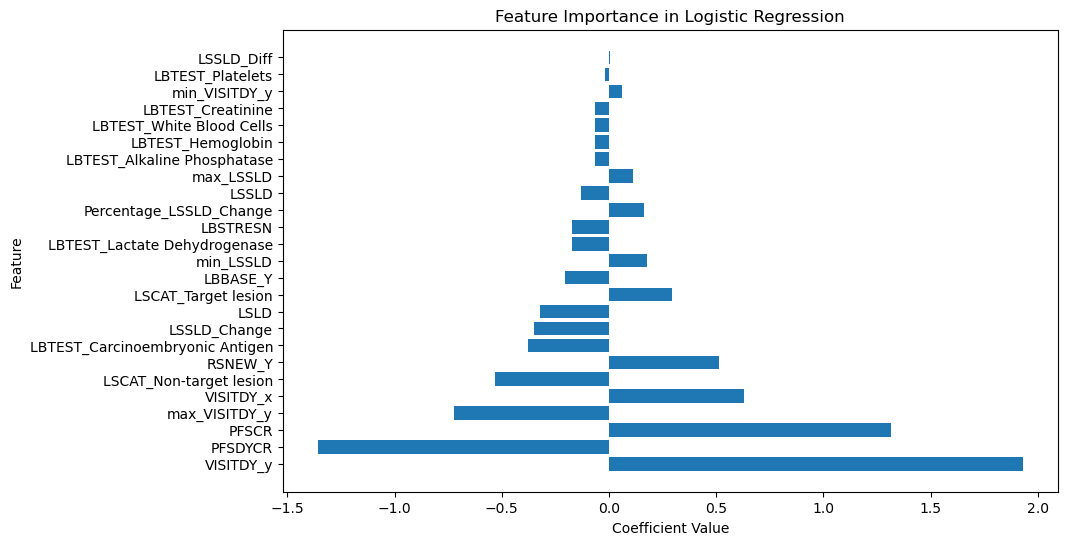

In [269]:
if len(model13.coef_) == 1:
    coefficients = model13.coef_[0]
else:
    coefficients = np.mean(model13.coef_, axis=0)

if len(coefficients) != len(X.columns):
    print("Mismatch between number of coefficients and number of features!")
else:
    importance_df = pd.DataFrame({
        'Feature': X.columns,
        'Importance': coefficients
    })

    importance_df['Abs_Importance'] = np.abs(importance_df['Importance'])
    importance_df = importance_df.sort_values(by='Abs_Importance', ascending=False)

    print(importance_df[['Feature', 'Importance']])

    plt.figure(figsize=(10, 6))
    plt.barh(importance_df['Feature'], importance_df['Importance'])
    plt.xlabel('Coefficient Value')
    plt.ylabel('Feature')
    plt.title('Feature Importance in Logistic Regression')
    plt.show()

# Removing Overfitting by Cross Validation

In [271]:
X = result1.drop(columns=['SUBJID', 'LSNEWANY','LSNEW_Y','LSNEWANY_Y'])  
y = result1['LSNEWANY']

In [273]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [275]:
model14 = LogisticRegression()

In [277]:
cv_scores = cross_val_score(model14, X_train_scaled, y_train, cv=10)
print(f"Cross-validation scores: {cv_scores}")
print(f"Mean CV accuracy: {np.mean(cv_scores):.4f}")

Cross-validation scores: [0.72972973 0.59459459 0.67567568 0.59459459 0.67567568 0.72972973
 0.72222222 0.77777778 0.72222222 0.72222222]
Mean CV accuracy: 0.6944


In [279]:
model14.fit(X_train_scaled, y_train)

LogisticRegression()

In [281]:
y_test_pred = model14.predict(X_test_scaled)

In [283]:
# Evaluate the model on test data
test_accuracy = accuracy_score(y_test, y_test_pred)
print(f"Test Accuracy: {test_accuracy:.4f}")

Test Accuracy: 0.7283


In [285]:
print("\nConfusion Matrix on Test Data:")
print(confusion_matrix(y_test, y_test_pred))

print("\nClassification Report on Test Data:")
print(classification_report(y_test, y_test_pred))


Confusion Matrix on Test Data:
[[63  5]
 [20  4]]

Classification Report on Test Data:
              precision    recall  f1-score   support

           0       0.76      0.93      0.83        68
           1       0.44      0.17      0.24        24

    accuracy                           0.73        92
   macro avg       0.60      0.55      0.54        92
weighted avg       0.68      0.73      0.68        92



In [287]:
y_train_pred = model14.predict(X_train_scaled)

y_test_pred = model14.predict(X_test_scaled)

train_accuracy = accuracy_score(y_train, y_train_pred)
test_accuracy = accuracy_score(y_test, y_test_pred)

print(f"Training Accuracy: {train_accuracy:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")

if train_accuracy > test_accuracy:
    print("\nPotential Overfitting Detected!")
else:
    print("\nNo Overfitting Detected!")

Training Accuracy: 0.7295
Test Accuracy: 0.7283

Potential Overfitting Detected!


# Feature Importance

In [291]:
X = result1.drop(columns=['SUBJID', 'LSNEWANY','LSNEW_Y','LSNEWANY_Y'])  
print("Shape of model coefficients:", model14.coef_.shape)
print("Number of features:", X.shape[1])

Shape of model coefficients: (1, 39)
Number of features: 39


                            Feature  Importance
14                          RSNEW_Y    1.676964
11                        VISITDY_y    1.499522
12                          PFSDYCR   -1.455280
13                            PFSCR    1.283880
8                         VISITDY_x    0.690775
28          LSSITE_Gastrointestinal   -0.456754
2                     max_VISITDY_y   -0.407125
15          LSCAT_Non-target lesion   -0.376398
32           LSSITE_Musculoskeletal   -0.351590
36                      LSSITE_Skin   -0.344807
6                      LSSLD_Change   -0.339275
10                             LSLD   -0.300806
1                         min_LSSLD    0.240962
5           Percentage_LSSLD_Change    0.236320
31               LSSITE_Lymph Nodes   -0.231326
29                LSSITE_HEENT/Neck    0.231116
34               LSSITE_Pelvic Site   -0.208884
22     LBTEST_Lactate Dehydrogenase   -0.204674
17                         LBBASE_Y   -0.187615
7                          LBSTRESN   -0

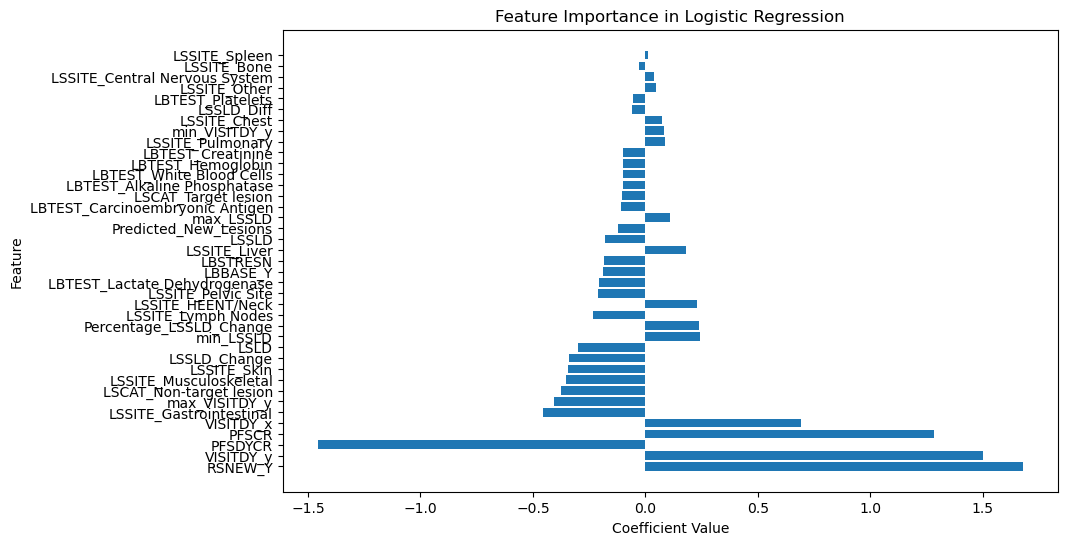

In [293]:
if len(model14.coef_) == 1:
    coefficients = model14.coef_[0]
else:
    coefficients = np.mean(model14.coef_, axis=0)

if len(coefficients) != len(X.columns):
    print("Mismatch between number of coefficients and number of features!")
else:
    importance_df = pd.DataFrame({
        'Feature': X.columns,
        'Importance': coefficients
    })

    importance_df['Abs_Importance'] = np.abs(importance_df['Importance'])
    importance_df = importance_df.sort_values(by='Abs_Importance', ascending=False)

    print(importance_df[['Feature', 'Importance']])

    plt.figure(figsize=(10, 6))
    plt.barh(importance_df['Feature'], importance_df['Importance'])
    plt.xlabel('Coefficient Value')
    plt.ylabel('Feature')
    plt.title('Feature Importance in Logistic Regression')
    plt.show()

# XGBoost for New Lesions

pip install xgboost

In [295]:
import xgboost as xgb

In [297]:
result1= result1.drop(columns=['Predicted_New_Lesions'])

In [299]:
features = result1.drop(columns=['SUBJID', 'LSNEWANY'])  
target = result1['LSNEWANY']

In [301]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(features)

In [303]:
X_train, X_test, y_train, y_test = train_test_split(X_scaled, target, test_size=0.2, random_state=42)

In [305]:
# Initialize and fit the XGBoost model
model18 = xgb.XGBClassifier(use_label_encoder=False, eval_metric='logloss')
model18.fit(X_train, y_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric='logloss',
              feature_types=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=None, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=None,
              n_jobs=None, num_parallel_tree=None, random_state=None, ...)

In [307]:
# Predict on the test set
y_pred = model18.predict(X_test)

In [309]:
accuracy = accuracy_score(y_test, y_pred)
conf_matrix = confusion_matrix(y_test, y_pred)
class_report = classification_report(y_test, y_pred)

In [311]:
print(f"Accuracy: {accuracy:.4f}")
print("Confusion Matrix:")
print(conf_matrix)
print("Classification Report:")
print(class_report)

Accuracy: 0.5000
Confusion Matrix:
[[39 29]
 [17  7]]
Classification Report:
              precision    recall  f1-score   support

           0       0.70      0.57      0.63        68
           1       0.19      0.29      0.23        24

    accuracy                           0.50        92
   macro avg       0.45      0.43      0.43        92
weighted avg       0.57      0.50      0.53        92



In [313]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

y_train_pred = model18.predict(X_train_scaled)

y_test_pred = model18.predict(X_test_scaled)

train_accuracy = accuracy_score(y_train, y_train_pred)
test_accuracy = accuracy_score(y_test, y_test_pred)

print(f"Training Accuracy: {train_accuracy:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")

if train_accuracy > test_accuracy:
    print("\nPotential Overfitting Detected!")
else:
    print("\nNo Overfitting Detected!")

Training Accuracy: 0.7869
Test Accuracy: 0.5109

Potential Overfitting Detected!


In [315]:
# Make predictions on the full dataset
full_predictions = model18.predict(X_scaled)

In [317]:
# Create DataFrame with predictions
result1['Predicted_New_Lesions'] = full_predictions

In [319]:
# Keep only the first prediction for each SUBJID
unique_predictions_df = result1.drop_duplicates(subset='SUBJID')[['SUBJID', 'LSNEWANY', 'Predicted_New_Lesions']]

In [321]:
print(unique_predictions_df)

         SUBJID  LSNEWANY  Predicted_New_Lesions
0             3         0                      1
1008          7         0                      0
12320         9         0                      0
18592        13         0                      0
20176        15         0                      0
25552        17         0                      0
28720        20         0                      0
29168        24         0                      0
30688        25         0                      0
32263        27         0                      0
32519        31         0                      0
46439        35         0                      1
48103        37         0                      1
78583        39         0                      0
81303        40         0                      0
86103        41         0                      0
92007        42         0                      0
96903        53         0                      0
101063       63         0                      0
103111       67     

# Feature Importance

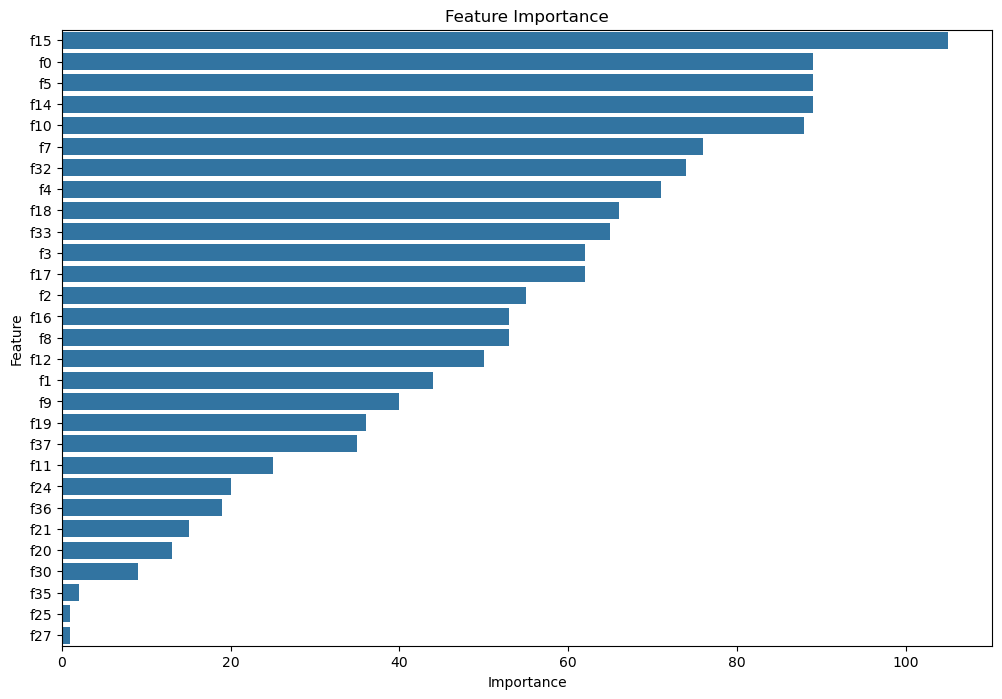

In [332]:
importances = model18.get_booster().get_score(importance_type='weight')
feature_importance = pd.DataFrame({
    'Feature': importances.keys(),
    'Importance': importances.values()
})

feature_importance = feature_importance.sort_values(by='Importance', ascending=False)

plt.figure(figsize=(12, 8))
sns.barplot(x='Importance', y='Feature', data=feature_importance)
plt.title('Feature Importance')
plt.show()



# Hyperparameter Tuning and Regularization

X = result1.drop(columns=['SUBJID', 'LSNEWANY','LSNEW_Y','LSNEWANY_Y'])  
y = result1['LSNEWANY']

In [354]:
X, y = make_classification(n_samples=1000, n_features=20, random_state=42)
X = result1.drop(columns=['SUBJID', 'LSNEWANY','LSNEW_Y','LSNEWANY_Y','Predicted_New_Lesions','min_VISITDY_y','min_LSSLD','max_VISITDY_y','max_LSSLD','LSSLD_Diff','LBTEST_Alkaline Phosphatase','LBTEST_Carcinoembryonic Antigen','LBTEST_Creatinine','LBTEST_Hemoglobin','LBTEST_Lactate Dehydrogenase','LBTEST_Platelets','LBTEST_White Blood Cells','Percentage_LSSLD_Change','LSCAT_Non-target lesion','LSCAT_Target lesion','LBBASE_Y','RSNEW_Y','LBBASE_Y','VISITDY_x'])  
y = result1['LSNEWANY']

In [356]:
X

,LSSLD_Change,LBSTRESN,LSSLD,LSLD,VISITDY_y,PFSDYCR,PFSCR,LSSITE_Bone,LSSITE_Central Nervous System,LSSITE_Chest,LSSITE_Gastrointestinal,LSSITE_HEENT/Neck,LSSITE_Liver,LSSITE_Lymph Nodes,LSSITE_Musculoskeletal,LSSITE_Other,LSSITE_Pelvic Site,LSSITE_Pulmonary,LSSITE_Skin,LSSITE_Spleen
0,0,135.910100,99.000000,35.727273,33.000000,54.0,1.0,0,48,0,0,0,528,144,0,96,0,96,0,0
27,0,135.910100,99.000000,35.727273,33.000000,54.0,1.0,0,48,0,0,0,528,144,0,96,0,96,0,0
1008,1,153.863690,284.521127,40.117647,171.571429,339.0,1.0,0,0,0,0,0,6272,4256,0,0,0,784,0,0
12320,1,112.913064,44.071429,20.142857,175.000000,301.0,1.0,0,0,0,0,0,784,3920,0,0,784,784,0,0
18592,0,190.772448,206.210526,35.000000,49.000000,73.0,1.0,0,0,0,96,0,1008,192,0,0,96,96,0,0
18637,0,190.772448,206.210526,35.000000,49.000000,73.0,1.0,0,0,0,96,0,1008,192,0,0,96,96,0,0
20176,1,97.912880,93.613636,23.909091,140.500000,414.0,1.0,0,0,0,0,0,2304,0,0,0,0,3072,0,0
25552,1,88.209722,46.190476,23.095238,147.333333,226.0,0.0,0,0,0,0,0,2592,576,0,0,0,0,0,0
28720,0,121.011607,117.600000,47.600000,28.000000,56.0,1.0,0,0,0,0,0,384,64,0,0,0,0,0,0
29168,1,121.885268,54.153846,30.923077,166.600000,306.0,1.0,0,0,0,0,0,1520,0,0,0,0,0,0,0


In [357]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

model15 = LogisticRegression()

In [360]:
param_grid = {
    'C': [0.001, 0.01, 0.1, 1.0, 10.0, 100.0],  # Regularization parameter
    'penalty': ['l1', 'l2']  # Penalty term ('l1' for Lasso, 'l2' for Ridge)
}

In [362]:
grid_search = GridSearchCV(estimator=model15, param_grid=param_grid, cv=5, scoring='accuracy')
grid_search.fit(X_train_scaled, y_train)

# Get the best model from grid search
best_model = grid_search.best_estimator_

In [363]:
best_model.fit(X_train_scaled, y_train)

LogisticRegression(C=0.1)

In [366]:
y_test_pred = best_model.predict(X_test_scaled)

# Evaluate the best model on test data
test_accuracy = accuracy_score(y_test, y_test_pred)
print(f"Test Accuracy: {test_accuracy:.4f}")

print("\nConfusion Matrix on Test Data:")
print(confusion_matrix(y_test, y_test_pred))

print("\nClassification Report on Test Data:")
print(classification_report(y_test, y_test_pred))


Test Accuracy: 0.6848

Confusion Matrix on Test Data:
[[62  6]
 [23  1]]

Classification Report on Test Data:
              precision    recall  f1-score   support

           0       0.73      0.91      0.81        68
           1       0.14      0.04      0.06        24

    accuracy                           0.68        92
   macro avg       0.44      0.48      0.44        92
weighted avg       0.58      0.68      0.62        92



In [368]:
print("\nBest Hyperparameters:")
print(grid_search.best_params_)


Best Hyperparameters:
{'C': 0.1, 'penalty': 'l2'}


In [370]:
y_train_pred = best_model.predict(X_train_scaled)

y_test_pred = best_model.predict(X_test_scaled)

train_accuracy = accuracy_score(y_train, y_train_pred)
test_accuracy = accuracy_score(y_test, y_test_pred)

print(f"Training Accuracy: {train_accuracy:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")

Training Accuracy: 0.7377
Test Accuracy: 0.6848


# Feature Importance

In [372]:
X = result1.drop(columns=['SUBJID', 'LSNEWANY','LSNEW_Y','LSNEWANY_Y'])  
print("Shape of model coefficients:", model14.coef_.shape)
print("Number of features:", X.shape[1])

Shape of model coefficients: (1, 39)
Number of features: 39


                            Feature  Importance
14                          RSNEW_Y    1.676964
11                        VISITDY_y    1.499522
12                          PFSDYCR   -1.455280
13                            PFSCR    1.283880
8                         VISITDY_x    0.690775
28          LSSITE_Gastrointestinal   -0.456754
2                     max_VISITDY_y   -0.407125
15          LSCAT_Non-target lesion   -0.376398
32           LSSITE_Musculoskeletal   -0.351590
36                      LSSITE_Skin   -0.344807
6                      LSSLD_Change   -0.339275
10                             LSLD   -0.300806
1                         min_LSSLD    0.240962
5           Percentage_LSSLD_Change    0.236320
31               LSSITE_Lymph Nodes   -0.231326
29                LSSITE_HEENT/Neck    0.231116
34               LSSITE_Pelvic Site   -0.208884
22     LBTEST_Lactate Dehydrogenase   -0.204674
17                         LBBASE_Y   -0.187615
7                          LBSTRESN   -0

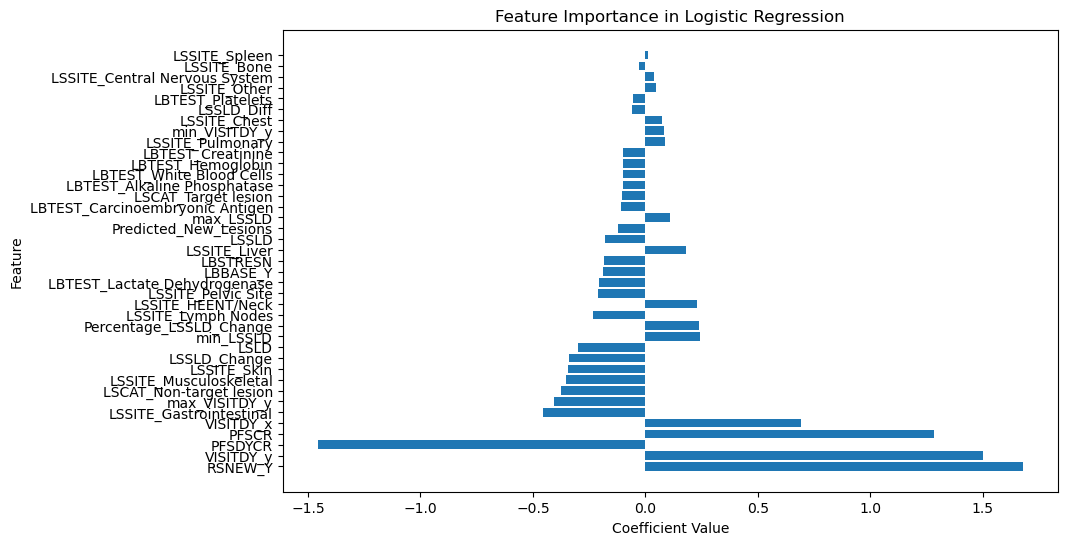

In [377]:
if len(model14.coef_) == 1:
    coefficients = model14.coef_[0]
else:
    coefficients = np.mean(model14.coef_, axis=0)

if len(coefficients) != len(X.columns):
    print("Mismatch between number of coefficients and number of features!")
else:
    importance_df = pd.DataFrame({
        'Feature': X.columns,
        'Importance': coefficients
    })

    importance_df['Abs_Importance'] = np.abs(importance_df['Importance'])
    importance_df = importance_df.sort_values(by='Abs_Importance', ascending=False)

    print(importance_df[['Feature', 'Importance']])

    plt.figure(figsize=(10, 6))
    plt.barh(importance_df['Feature'], importance_df['Importance'])
    plt.xlabel('Coefficient Value')
    plt.ylabel('Feature')
    plt.title('Feature Importance in Logistic Regression')
    plt.show()

# Removing Overfitting by Elastic Net

In [379]:
X = result1.drop(columns=['SUBJID', 'LSNEWANY','LSNEW_Y','LSNEWANY_Y'])  
y = result1['LSNEWANY']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
param_grid = {
    'penalty': ['elasticnet'],
    'solver': ['saga'],
    'l1_ratio': [0.1, 0.5, 0.7, 0.9],  # L1 ratio for elastic net (0 means Ridge, 1 means Lasso)
    'C': [0.1, 1.0, 10.0]  # Regularization parameter
}

In [381]:
model16 = GridSearchCV(LogisticRegression(max_iter=1000), param_grid, cv=10, scoring='accuracy')

In [383]:
model16.fit(X_train_scaled, y_train)

GridSearchCV(cv=10, estimator=LogisticRegression(max_iter=1000),
             param_grid={'C': [0.1, 1.0, 10.0],
                         'l1_ratio': [0.1, 0.5, 0.7, 0.9],
                         'penalty': ['elasticnet'], 'solver': ['saga']},
             scoring='accuracy')

In [384]:
best_model = model16.best_estimator_
y_train_pred = best_model.predict(X_train_scaled)
y_test_pred = best_model.predict(X_test_scaled)

In [385]:
train_accuracy = accuracy_score(y_train, y_train_pred)
test_accuracy = accuracy_score(y_test, y_test_pred)

print(f"Training Accuracy: {train_accuracy:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")

# Compare training and test accuracy
if train_accuracy > test_accuracy:
    print("\nPotential Overfitting Detected!")
else:
    print("\nNo Overfitting Detected!")

Training Accuracy: 0.7896
Test Accuracy: 0.5000

Potential Overfitting Detected!


In [386]:
print("\nBest Parameters:")
print(model16.best_params_)


Best Parameters:
{'C': 0.1, 'l1_ratio': 0.9, 'penalty': 'elasticnet', 'solver': 'saga'}


In [387]:
# Cross-validation to further evaluate model performance
cv_scores = cross_val_score(best_model, X_train_scaled, y_train, cv=5)
print(f"\nCross-validation scores: {cv_scores}")
print(f"Mean CV accuracy: {np.mean(cv_scores):.4f} (+/- {np.std(cv_scores):.4f})")


Cross-validation scores: [0.74324324 0.80821918 0.84931507 0.80821918 0.7260274 ]
Mean CV accuracy: 0.7870 (+/- 0.0456)


In [388]:
# Other metrics
print("\nClassification Report on Test Data:")
print(classification_report(y_test, y_test_pred))

print("\nConfusion Matrix on Test Data:")
print(confusion_matrix(y_test, y_test_pred))


Classification Report on Test Data:
              precision    recall  f1-score   support

           0       0.70      0.57      0.63        68
           1       0.19      0.29      0.23        24

    accuracy                           0.50        92
   macro avg       0.45      0.43      0.43        92
weighted avg       0.57      0.50      0.53        92


Confusion Matrix on Test Data:
[[39 29]
 [17  7]]


# Feature Importance

                            Feature  Importance
14                          RSNEW_Y    1.676964
11                        VISITDY_y    1.499522
12                          PFSDYCR   -1.455280
13                            PFSCR    1.283880
8                         VISITDY_x    0.690775
28          LSSITE_Gastrointestinal   -0.456754
2                     max_VISITDY_y   -0.407125
15          LSCAT_Non-target lesion   -0.376398
32           LSSITE_Musculoskeletal   -0.351590
36                      LSSITE_Skin   -0.344807
6                      LSSLD_Change   -0.339275
10                             LSLD   -0.300806
1                         min_LSSLD    0.240962
5           Percentage_LSSLD_Change    0.236320
31               LSSITE_Lymph Nodes   -0.231326
29                LSSITE_HEENT/Neck    0.231116
34               LSSITE_Pelvic Site   -0.208884
22     LBTEST_Lactate Dehydrogenase   -0.204674
17                         LBBASE_Y   -0.187615
7                          LBSTRESN   -0

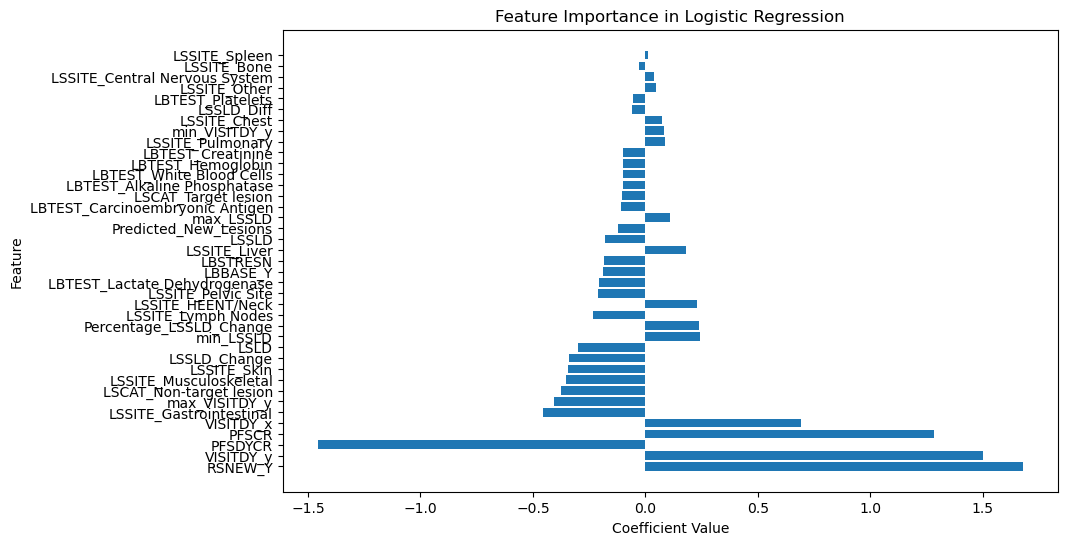

In [396]:
if len(model14.coef_) == 1:
    coefficients = model14.coef_[0]
else:
    coefficients = np.mean(model14.coef_, axis=0)

if len(coefficients) != len(X.columns):
    print("Mismatch between number of coefficients and number of features!")
else:
    importance_df = pd.DataFrame({
        'Feature': X.columns,
        'Importance': coefficients
    })

    importance_df['Abs_Importance'] = np.abs(importance_df['Importance'])
    importance_df = importance_df.sort_values(by='Abs_Importance', ascending=False)

    print(importance_df[['Feature', 'Importance']])

    plt.figure(figsize=(10, 6))
    plt.barh(importance_df['Feature'], importance_df['Importance'])
    plt.xlabel('Coefficient Value')
    plt.ylabel('Feature')
    plt.title('Feature Importance in Logistic Regression')
    plt.show()

# Logistic Regression for Increase in Tumour Size

In [408]:
result1.head()

,SUBJID,LSNEWANY,min_VISITDY_y,min_LSSLD,max_VISITDY_y,max_LSSLD,LSSLD_Diff,Percentage_LSSLD_Change,LSSLD_Change,LBSTRESN,VISITDY_x,LSSLD,LSLD,VISITDY_y,PFSDYCR,PFSCR,LSNEW_Y,LSNEWANY_Y,RSNEW_Y,LSCAT_Non-target lesion,LSCAT_Target lesion,LBBASE_Y,LBTEST_Alkaline Phosphatase,LBTEST_Carcinoembryonic Antigen,LBTEST_Creatinine,LBTEST_Hemoglobin,LBTEST_Lactate Dehydrogenase,LBTEST_Platelets,LBTEST_White Blood Cells,LSSITE_Bone,LSSITE_Central Nervous System,LSSITE_Chest,LSSITE_Gastrointestinal,LSSITE_HEENT/Neck,LSSITE_Liver,LSSITE_Lymph Nodes,LSSITE_Musculoskeletal,LSSITE_Other,LSSITE_Pelvic Site,LSSITE_Pulmonary,LSSITE_Skin,LSSITE_Spleen,Predicted_New_Lesions
0,3,0,-11.0,65.0,55.0,118.0,53.0,44.915254,0,135.910100,26.714286,99.000000,35.727273,33.000000,54.0,1.0,48,288,336,480,480,504,126,126,126,126,126,126,126,0,48,0,0,0,528,144,0,96,0,96,0,0,1
27,3,1,-11.0,65.0,55.0,118.0,53.0,44.915254,0,135.910100,26.714286,99.000000,35.727273,33.000000,54.0,1.0,48,288,336,480,480,504,126,126,126,126,126,126,126,0,48,0,0,0,528,144,0,96,0,96,0,0,1
1008,7,0,-14.0,136.0,343.0,575.0,439.0,76.347826,1,153.863690,169.257426,284.521127,40.117647,171.571429,339.0,1.0,0,0,0,1568,9744,5656,1414,1414,1414,1414,1414,1414,1414,0,0,0,0,0,6272,4256,0,0,0,784,0,0,0
12320,9,0,-2.0,30.0,344.0,85.0,55.0,64.705882,1,112.913064,175.000000,44.071429,20.142857,175.000000,301.0,1.0,0,0,0,3136,3136,3136,784,784,784,784,784,784,784,0,0,0,0,0,784,3920,0,0,784,784,0,0,0
18592,13,0,-1.0,166.0,74.0,238.0,72.0,30.252101,0,190.772448,39.909091,206.210526,35.000000,49.000000,73.0,1.0,96,864,528,576,912,792,198,198,198,198,198,198,198,0,0,0,96,0,1008,192,0,0,96,96,0,0,0


In [410]:
#result1= result1.drop(columns=['Predicted_New_Lesions'])

In [412]:
result1.columns

Index(['SUBJID', 'LSNEWANY', 'min_VISITDY_y', 'min_LSSLD', 'max_VISITDY_y', 'max_LSSLD', 'LSSLD_Diff', 'Percentage_LSSLD_Change', 'LSSLD_Change', 'LBSTRESN', 'VISITDY_x', 'LSSLD', 'LSLD', 'VISITDY_y', 'PFSDYCR', 'PFSCR', 'LSNEW_Y', 'LSNEWANY_Y', 'RSNEW_Y', 'LSCAT_Non-target lesion', 'LSCAT_Target lesion', 'LBBASE_Y', 'LBTEST_Alkaline Phosphatase', 'LBTEST_Carcinoembryonic Antigen', 'LBTEST_Creatinine', 'LBTEST_Hemoglobin', 'LBTEST_Lactate Dehydrogenase', 'LBTEST_Platelets', 'LBTEST_White Blood Cells', 'LSSITE_Bone', 'LSSITE_Central Nervous System', 'LSSITE_Chest', 'LSSITE_Gastrointestinal', 'LSSITE_HEENT/Neck', 'LSSITE_Liver', 'LSSITE_Lymph Nodes', 'LSSITE_Musculoskeletal', 'LSSITE_Other', 'LSSITE_Pelvic Site', 'LSSITE_Pulmonary', 'LSSITE_Skin', 'LSSITE_Spleen', 'Predicted_New_Lesions'], dtype='object')

In [414]:
X = result1[['SUBJID','LSNEWANY','LBSTRESN','PFSDYCR', 'PFSCR', 'RSNEW_Y', 'LSCAT_Non-target lesion', 'LSCAT_Target lesion', 'LBBASE_Y', 'LBTEST_Alkaline Phosphatase', 'LBTEST_Carcinoembryonic Antigen', 'LBTEST_Creatinine', 'LBTEST_Hemoglobin', 'LBTEST_Lactate Dehydrogenase', 'LBTEST_Platelets', 'LBTEST_White Blood Cells', 'LSSITE_Bone', 'LSSITE_Central Nervous System', 'LSSITE_Chest', 'LSSITE_Gastrointestinal', 'LSSITE_HEENT/Neck', 'LSSITE_Liver', 'LSSITE_Lymph Nodes', 'LSSITE_Musculoskeletal','LSSITE_Other', 'LSSITE_Pelvic Site', 'LSSITE_Pulmonary', 'LSSITE_Skin', 'LSSITE_Spleen']]
y = result1['LSSLD_Change']

In [416]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [418]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [420]:
model21 = LogisticRegression()

In [422]:
model21.fit(X_train_scaled, y_train)

LogisticRegression()

In [424]:
y_pred = model21.predict(X_test_scaled)

In [426]:
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy:.4f}")

Accuracy: 0.7717


In [428]:
conf_matrix = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:")
print(conf_matrix)

Confusion Matrix:
[[23  9]
 [12 48]]


In [430]:
class_report = classification_report(y_test, y_pred)
print("Classification Report:")
print(class_report)

Classification Report:
              precision    recall  f1-score   support

           0       0.66      0.72      0.69        32
           1       0.84      0.80      0.82        60

    accuracy                           0.77        92
   macro avg       0.75      0.76      0.75        92
weighted avg       0.78      0.77      0.77        92



In [432]:
result1['Predicted_LSSLD_Change'] = model21.predict(scaler.transform(X))

predictions1 = result1.drop_duplicates(subset='SUBJID')[['SUBJID', 'LSSLD_Change', 'Predicted_LSSLD_Change']]

In [434]:
predictions1.head(20)

,SUBJID,LSSLD_Change,Predicted_LSSLD_Change
0,3,0,0
1008,7,1,1
12320,9,1,1
18592,13,0,0
20176,15,1,1
25552,17,1,1
28720,20,0,0
29168,24,1,0
30688,25,0,1
32263,27,0,0


# Feature Importance

                            Feature  Importance
7               LSCAT_Target lesion    1.615126
6           LSCAT_Non-target lesion   -1.168682
5                           RSNEW_Y   -0.970030
2                          LBSTRESN   -0.882890
21                     LSSITE_Liver    0.667980
10  LBTEST_Carcinoembryonic Antigen    0.608897
25               LSSITE_Pelvic Site   -0.445444
17    LSSITE_Central Nervous System    0.350253
24                     LSSITE_Other    0.348876
8                          LBBASE_Y    0.332899
3                           PFSDYCR    0.238558
11                LBTEST_Creatinine    0.217530
12                LBTEST_Hemoglobin    0.217530
15         LBTEST_White Blood Cells    0.217530
9       LBTEST_Alkaline Phosphatase    0.210322
23           LSSITE_Musculoskeletal    0.190775
19          LSSITE_Gastrointestinal    0.179629
20                LSSITE_HEENT/Neck   -0.174600
14                 LBTEST_Platelets    0.157515
28                    LSSITE_Spleen    0

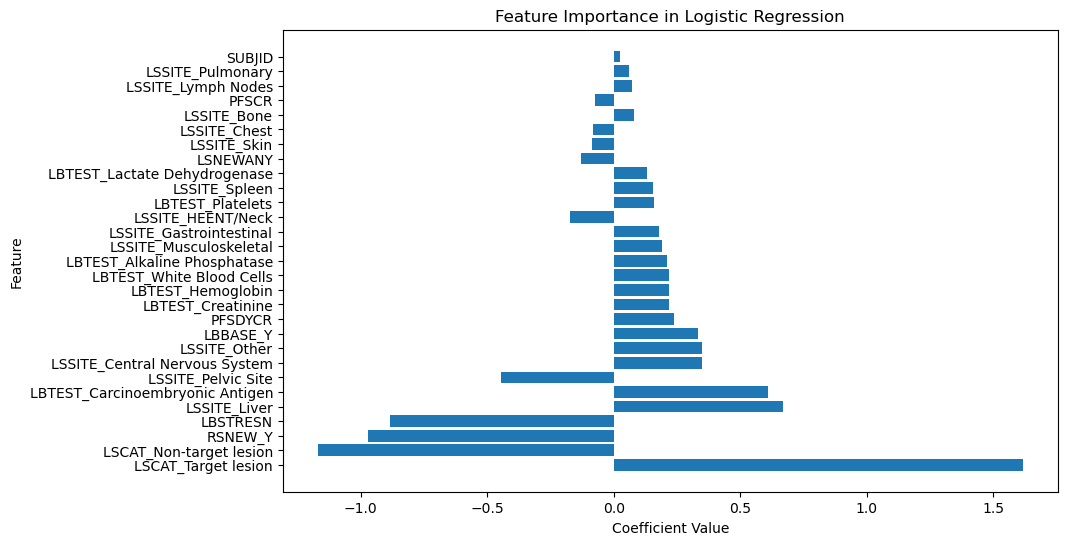

In [440]:
if len(model21.coef_) == 1:
    coefficients = model21.coef_[0]
else:
    coefficients = np.mean(model21.coef_, axis=0)

if len(coefficients) != len(X.columns):
    print("Mismatch between number of coefficients and number of features!")
else:
    importance_df = pd.DataFrame({
        'Feature': X.columns,
        'Importance': coefficients
    })

    importance_df['Abs_Importance'] = np.abs(importance_df['Importance'])
    importance_df = importance_df.sort_values(by='Abs_Importance', ascending=False)

    print(importance_df[['Feature', 'Importance']])

    plt.figure(figsize=(10, 6))
    plt.barh(importance_df['Feature'], importance_df['Importance'])
    plt.xlabel('Coefficient Value')
    plt.ylabel('Feature')
    plt.title('Feature Importance in Logistic Regression')
    plt.show()

# Removing Overfitting by Cross Validation

In [442]:
X = result1[['SUBJID','LSNEWANY','LBSTRESN','PFSDYCR', 'PFSCR', 'RSNEW_Y', 'LSCAT_Non-target lesion', 'LSCAT_Target lesion', 'LBBASE_Y', 'LBTEST_Alkaline Phosphatase', 'LBTEST_Carcinoembryonic Antigen', 'LBTEST_Creatinine', 'LBTEST_Hemoglobin', 'LBTEST_Lactate Dehydrogenase', 'LBTEST_Platelets', 'LBTEST_White Blood Cells', 'LSSITE_Bone', 'LSSITE_Central Nervous System', 'LSSITE_Chest', 'LSSITE_Gastrointestinal', 'LSSITE_HEENT/Neck', 'LSSITE_Liver', 'LSSITE_Lymph Nodes', 'LSSITE_Musculoskeletal','LSSITE_Other', 'LSSITE_Pelvic Site', 'LSSITE_Pulmonary', 'LSSITE_Skin', 'LSSITE_Spleen']]
y = result1['LSSLD_Change']
X, y = make_classification(n_samples=1000, n_features=20, random_state=42)

In [444]:
# Split the dataset into training and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [446]:
# Standardize the features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [448]:
# Initialize the model with regularization (L2 regularization by default)
model22 = LogisticRegression()

In [450]:
cv_scores = cross_val_score(model22, X_train_scaled, y_train, cv=5)
print(f"Cross-validation scores: {cv_scores}")
print(f"Mean CV accuracy: {np.mean(cv_scores):.4f}")

Cross-validation scores: [0.85625 0.875   0.85625 0.86875 0.88125]
Mean CV accuracy: 0.8675


In [452]:
# Fit the model on the training data
model22.fit(X_train_scaled, y_train)

LogisticRegression()

In [454]:
# Predict on the test data
y_test_pred = model22.predict(X_test_scaled)

In [456]:
# Evaluate the model on test data
test_accuracy = accuracy_score(y_test, y_test_pred)
print(f"Test Accuracy: {test_accuracy:.4f}")

Test Accuracy: 0.8550


In [458]:
print("\nConfusion Matrix on Test Data:")
print(confusion_matrix(y_test, y_test_pred))

print("\nClassification Report on Test Data:")
print(classification_report(y_test, y_test_pred))


Confusion Matrix on Test Data:
[[85  8]
 [21 86]]

Classification Report on Test Data:
              precision    recall  f1-score   support

           0       0.80      0.91      0.85        93
           1       0.91      0.80      0.86       107

    accuracy                           0.85       200
   macro avg       0.86      0.86      0.85       200
weighted avg       0.86      0.85      0.86       200



In [462]:
y_train_pred = model22.predict(X_train_scaled)

y_test_pred = model22.predict(X_test_scaled)

train_accuracy = accuracy_score(y_train, y_train_pred)
test_accuracy = accuracy_score(y_test, y_test_pred)

print(f"Training Accuracy: {train_accuracy:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")

Training Accuracy: 0.8825
Test Accuracy: 0.8550


# Feature Importance

In [475]:
X = result1[['SUBJID','LSNEWANY','LBSTRESN','PFSDYCR', 'PFSCR', 'RSNEW_Y', 'LSCAT_Non-target lesion', 'LSCAT_Target lesion', 'LBBASE_Y', 'LBTEST_Alkaline Phosphatase', 'LBTEST_Carcinoembryonic Antigen', 'LBTEST_Creatinine', 'LBTEST_Hemoglobin', 'LBTEST_Lactate Dehydrogenase', 'LBTEST_Platelets', 'LBTEST_White Blood Cells', 'LSSITE_Bone', 'LSSITE_Central Nervous System', 'LSSITE_Chest', 'LSSITE_Gastrointestinal', ]]

In [477]:
print("Shape of model coefficients:", model22.coef_.shape)
print("Number of features:", X.shape[1])

Shape of model coefficients: (1, 20)
Number of features: 20


                            Feature  Importance
5                           RSNEW_Y    1.628155
18                     LSSITE_Chest   -1.191763
14                 LBTEST_Platelets   -0.924301
1                          LSNEWANY   -0.572316
11                LBTEST_Creatinine    0.440286
2                          LBSTRESN    0.228404
10  LBTEST_Carcinoembryonic Antigen    0.206618
17    LSSITE_Central Nervous System   -0.148992
13     LBTEST_Lactate Dehydrogenase    0.136783
19          LSSITE_Gastrointestinal    0.108737
3                           PFSDYCR    0.100259
0                            SUBJID    0.093390
6           LSCAT_Non-target lesion   -0.084928
15         LBTEST_White Blood Cells    0.080164
16                      LSSITE_Bone    0.070187
12                LBTEST_Hemoglobin    0.030687
4                             PFSCR   -0.023679
8                          LBBASE_Y   -0.023102
7               LSCAT_Target lesion   -0.018117
9       LBTEST_Alkaline Phosphatase    0

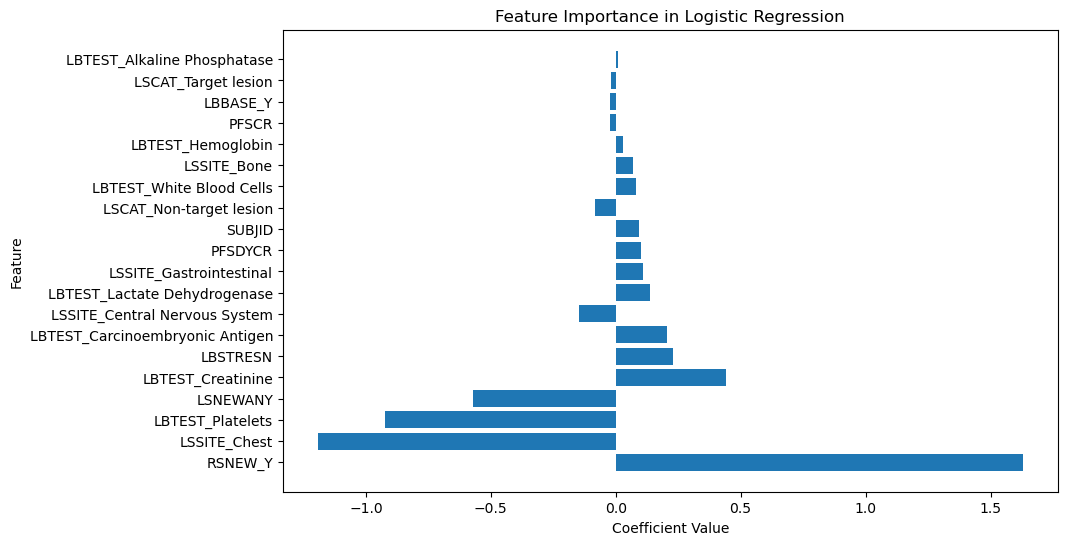

In [479]:
if len(model22.coef_) == 1:
    coefficients = model22.coef_[0]
else:
    coefficients = np.mean(model22.coef_, axis=0)

if len(coefficients) != len(X.columns):
    print("Mismatch between number of coefficients and number of features!")
else:
    importance_df = pd.DataFrame({
        'Feature': X.columns,
        'Importance': coefficients
    })

    importance_df['Abs_Importance'] = np.abs(importance_df['Importance'])
    importance_df = importance_df.sort_values(by='Abs_Importance', ascending=False)

    print(importance_df[['Feature', 'Importance']])

    plt.figure(figsize=(10, 6))
    plt.barh(importance_df['Feature'], importance_df['Importance'])
    plt.xlabel('Coefficient Value')
    plt.ylabel('Feature')
    plt.title('Feature Importance in Logistic Regression')
    plt.show()

# Solving Overfitting using Elastic Net

In [525]:
X = result1[['SUBJID','LSNEWANY','LBSTRESN','PFSDYCR', 'PFSCR', 'RSNEW_Y', 'LSCAT_Non-target lesion', 'LSCAT_Target lesion', 'LBBASE_Y', 'LBTEST_Alkaline Phosphatase', 'LBTEST_Carcinoembryonic Antigen', 'LBTEST_Creatinine', 'LBTEST_Hemoglobin', 'LBTEST_Lactate Dehydrogenase', 'LBTEST_Platelets', 'LBTEST_White Blood Cells', 'LSSITE_Bone', 'LSSITE_Central Nervous System', 'LSSITE_Chest', 'LSSITE_Gastrointestinal', 'LSSITE_HEENT/Neck', 'LSSITE_Liver', 'LSSITE_Lymph Nodes', 'LSSITE_Musculoskeletal','LSSITE_Other', 'LSSITE_Pelvic Site', 'LSSITE_Pulmonary', 'LSSITE_Skin', 'LSSITE_Spleen']]
y = result1['LSSLD_Change']

In [527]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [529]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [531]:
param_grid = {
    'penalty': ['elasticnet'],
    'solver': ['saga'],
    'l1_ratio': [0.1, 0.5, 0.7, 0.9],  # L1 ratio for elastic net (0 means Ridge, 1 means Lasso)
    'C': [0.1, 1.0, 10.0]  # Regularization parameter
}

In [533]:
model24= GridSearchCV(LogisticRegression(max_iter=1000), param_grid, cv=5, scoring='accuracy')

In [535]:
model24.fit(X_train_scaled, y_train)

GridSearchCV(cv=5, estimator=LogisticRegression(max_iter=1000),
             param_grid={'C': [0.1, 1.0, 10.0],
                         'l1_ratio': [0.1, 0.5, 0.7, 0.9],
                         'penalty': ['elasticnet'], 'solver': ['saga']},
             scoring='accuracy')

In [536]:
best_model = model24.best_estimator_

In [537]:
y_train_pred = best_model.predict(X_train_scaled)
y_test_pred = best_model.predict(X_test_scaled)

train_accuracy = accuracy_score(y_train, y_train_pred)
test_accuracy = accuracy_score(y_test, y_test_pred)

In [541]:
print(f"Training Accuracy: {train_accuracy:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")

print("\nBest Parameters:")
print(model24.best_params_)

if train_accuracy > test_accuracy:
    print("\nPotential Overfitting Detected!")
else:
    print("\nNo Overfitting Detected!")


Training Accuracy: 0.7923
Test Accuracy: 0.7609

Best Parameters:
{'C': 10.0, 'l1_ratio': 0.1, 'penalty': 'elasticnet', 'solver': 'saga'}

Potential Overfitting Detected!


In [543]:
cv_scores = cross_val_score(best_model, X_train_scaled, y_train, cv=5)
print(f"\nCross-validation scores: {cv_scores}")
print(f"Mean CV accuracy: {np.mean(cv_scores):.4f} (+/- {np.std(cv_scores):.4f})")

# Other metrics
print("\nClassification Report on Test Data:")
print(classification_report(y_test, y_test_pred))

print("\nConfusion Matrix on Test Data:")
print(confusion_matrix(y_test, y_test_pred))


Cross-validation scores: [0.83783784 0.69863014 0.8630137  0.75342466 0.7260274 ]
Mean CV accuracy: 0.7758 (+/- 0.0639)

Classification Report on Test Data:
              precision    recall  f1-score   support

           0       0.64      0.72      0.68        32
           1       0.84      0.78      0.81        60

    accuracy                           0.76        92
   macro avg       0.74      0.75      0.74        92
weighted avg       0.77      0.76      0.76        92


Confusion Matrix on Test Data:
[[23  9]
 [13 47]]


# Feature Importance

In [548]:
# Feature Importance (Coefficients)
feature_importance = best_model.coef_[0]
features = X.columns
feature_importance_df = pd.DataFrame({'Feature': features, 'Importance': feature_importance})

# Displaying feature importance
print("\nFeature Importance:")
print(feature_importance_df.sort_values(by='Importance', ascending=False))


Feature Importance:
                            Feature  Importance
7               LSCAT_Target lesion    2.039389
10  LBTEST_Carcinoembryonic Antigen    0.774620
21                     LSSITE_Liver    0.664594
17    LSSITE_Central Nervous System    0.433654
8                          LBBASE_Y    0.382115
24                     LSSITE_Other    0.347970
23           LSSITE_Musculoskeletal    0.337386
19          LSSITE_Gastrointestinal    0.324973
3                           PFSDYCR    0.243986
15         LBTEST_White Blood Cells    0.220648
11                LBTEST_Creatinine    0.220648
12                LBTEST_Hemoglobin    0.220648
9       LBTEST_Alkaline Phosphatase    0.210291
28                    LSSITE_Spleen    0.196310
22               LSSITE_Lymph Nodes    0.173269
14                 LBTEST_Platelets    0.136777
13     LBTEST_Lactate Dehydrogenase    0.100242
16                      LSSITE_Bone    0.080749
0                            SUBJID    0.037276
26                 

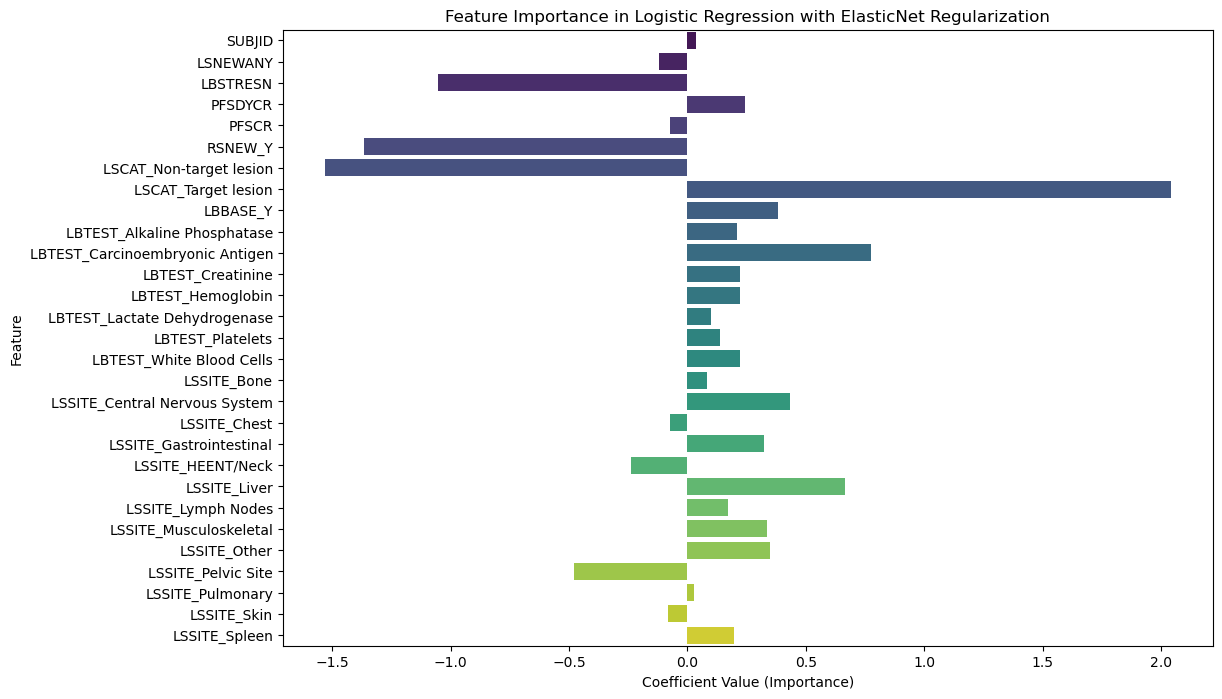

In [550]:
plt.figure(figsize=(12, 8))
sns.barplot(x='Importance', y='Feature', data=feature_importance_df, palette="viridis")
plt.title('Feature Importance in Logistic Regression with ElasticNet Regularization')
plt.xlabel('Coefficient Value (Importance)')
plt.ylabel('Feature')
plt.show()

# Changing the features choosen

In [552]:
X = result1[['SUBJID','LSNEWANY','LBSTRESN','PFSDYCR', 'PFSCR', 'RSNEW_Y', 'LSCAT_Non-target lesion', 'LSCAT_Target lesion', 'LBBASE_Y', 'LBTEST_Alkaline Phosphatase', 'LBTEST_Carcinoembryonic Antigen', 'LBTEST_Creatinine', 'LBTEST_Hemoglobin', 'LBTEST_Lactate Dehydrogenase', 'LBTEST_Platelets', 'LBTEST_White Blood Cells', 'LSSITE_Bone', 'LSSITE_Central Nervous System', 'LSSITE_Chest', 'LSSITE_Gastrointestinal', 'LSSITE_HEENT/Neck', 'LSSITE_Liver', 'LSSITE_Lymph Nodes', 'LSSITE_Musculoskeletal','LSSITE_Other', 'LSSITE_Pelvic Site', 'LSSITE_Pulmonary', 'LSSITE_Skin', 'LSSITE_Spleen']]
y = result1['LSSLD_Change']

In [554]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [556]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [558]:
model25 = LogisticRegression()

In [560]:
model25.fit(X_train_scaled, y_train)

LogisticRegression()

In [580]:
y_train_pred = model25.predict(X_train_scaled)
y_test_pred = model25.predict(X_test_scaled)

# Evaluate model performance
train_accuracy = accuracy_score(y_train, y_train_pred)
test_accuracy = accuracy_score(y_test, y_test_pred)

print(f"Training Accuracy: {train_accuracy:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")

Training Accuracy: 0.7923
Test Accuracy: 0.7717


In [565]:
y_pred = model25.predict(X_test_scaled)

In [567]:
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy:.4f}")

Accuracy: 0.7717


In [569]:
conf_matrix = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:")
print(conf_matrix)

Confusion Matrix:
[[23  9]
 [12 48]]


In [571]:
class_report = classification_report(y_test, y_pred)
print("Classification Report:")
print(class_report)

Classification Report:
              precision    recall  f1-score   support

           0       0.66      0.72      0.69        32
           1       0.84      0.80      0.82        60

    accuracy                           0.77        92
   macro avg       0.75      0.76      0.75        92
weighted avg       0.78      0.77      0.77        92



In [573]:
result1['Predicted_LSSLD_Change'] = model25.predict(scaler.transform(X))

predictions1 = result1.drop_duplicates(subset='SUBJID')[['SUBJID', 'LSSLD_Change', 'Predicted_LSSLD_Change']]

In [575]:
predictions1.head()

,SUBJID,LSSLD_Change,Predicted_LSSLD_Change
0,3,0,0
1008,7,1,1
12320,9,1,1
18592,13,0,0
20176,15,1,1


In [577]:
predictions1.to_csv("C:\\Users\\dpree\\Desktop\\Kolate.AI\\1183\\Regression Model (Tumour Size,New Lesions)\\Output\\Predictions for Change in Tumour Size.csv", index=False)
print("Saved.")

Saved.


# Feature Importance

                            Feature  Importance
7               LSCAT_Target lesion    1.615126
6           LSCAT_Non-target lesion   -1.168682
5                           RSNEW_Y   -0.970030
2                          LBSTRESN   -0.882890
21                     LSSITE_Liver    0.667980
10  LBTEST_Carcinoembryonic Antigen    0.608897
25               LSSITE_Pelvic Site   -0.445444
17    LSSITE_Central Nervous System    0.350253
24                     LSSITE_Other    0.348876
8                          LBBASE_Y    0.332899
3                           PFSDYCR    0.238558
11                LBTEST_Creatinine    0.217530
12                LBTEST_Hemoglobin    0.217530
15         LBTEST_White Blood Cells    0.217530
9       LBTEST_Alkaline Phosphatase    0.210322
23           LSSITE_Musculoskeletal    0.190775
19          LSSITE_Gastrointestinal    0.179629
20                LSSITE_HEENT/Neck   -0.174600
14                 LBTEST_Platelets    0.157515
28                    LSSITE_Spleen    0

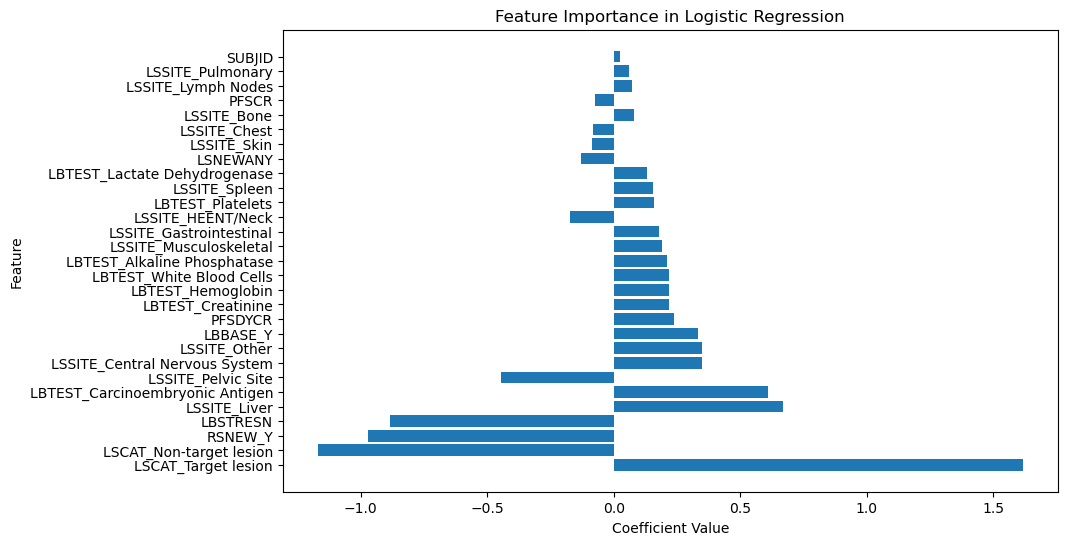

In [582]:
if len(model25.coef_) == 1:
    coefficients = model25.coef_[0]
else:
    coefficients = np.mean(model25.coef_, axis=0)

if len(coefficients) != len(X.columns):
    print("Mismatch between number of coefficients and number of features!")
else:
    importance_df = pd.DataFrame({
        'Feature': X.columns,
        'Importance': coefficients
    })

    importance_df['Abs_Importance'] = np.abs(importance_df['Importance'])
    importance_df = importance_df.sort_values(by='Abs_Importance', ascending=False)

    print(importance_df[['Feature', 'Importance']])

    plt.figure(figsize=(10, 6))
    plt.barh(importance_df['Feature'], importance_df['Importance'])
    plt.xlabel('Coefficient Value')
    plt.ylabel('Feature')
    plt.title('Feature Importance in Logistic Regression')
    plt.show()